# Avalon Simulation — Version 1 (probability-based baseline)

This notebook builds a modular Monte Carlo simulator for *The Resistance: Avalon*.
Version 1 is deliberately simple: players act on **fixed, tunable probabilities** and
only use their *private* knowledge (their role, and for evil, who their allies are).
Nobody reasons about the public history yet. That comes in later versions.

**Architecture.** Each layer only talks to the one next to it, so later versions can swap
one piece without touching the others.

| Layer | What it is | Changes in later versions? |
|---|---|---|
| 1. Roles & rules | Player counts, team sizes, fail thresholds | Add Merlin, Percival, Morgana, Assassin… |
| 2. Game state & public log | The ground truth plus the public record of proposals, votes, quest results | Rarely |
| 3. Information model | What each player is allowed to see (`PlayerView`) | Yes, special roles see more |
| 4. Agents / policies | `propose_team`, `vote_on_team`, `play_quest_card` | Yes, this is where nuance lives |
| 5. Engine | Runs one game, enforces the rules | Assassination phase in V3 |
| 6. Simulation & analysis | Runs many games, parameter sweeps | Grows with new metrics |

### Rules primer (what the engine implements)

1. **Setup.** 5–10 players are secretly dealt *good* or *evil* roles (roughly a third are evil).
   Evil players learn who their allies are; good players know only their own role.
2. **Team building.** The leader proposes a team for the current quest (team size is fixed
   by the player count and the quest number).
3. **Team vote.** *Everyone*, the leader included, votes approve or reject in public. A **strict majority**
   approves the team; a tie counts as a rejection. On rejection, leadership passes clockwise
   and a new team is proposed. **Five rejections in a row on one quest = evil wins.**
4. **Quest.** Each team member secretly plays a *success* or *fail* card. Good players **must**
   play success; evil players may choose either. Only the number of fail cards is revealed.
   One fail sinks the quest, except **quest 4 with 7+ players, which needs two fails**.
5. **End.** First side to 3 quests wins. Leadership also passes after an approved quest.

> **Scope note.** The official *basic* Avalon game also includes **Merlin** (a good player who
> knows the evil players) and the **Assassin** (an evil player who, if good wins 3 quests, gets
> one guess at Merlin; a correct guess steals the win for evil). V1 leaves them out, so
> mechanically it is the core loop shared with *The Resistance*. They are planned for V3 (see the roadmap at the end).

## 0. Imports

In [1]:
from __future__ import annotations

import random
from dataclasses import dataclass, field, replace, asdict
from enum import Enum
from typing import Callable, Protocol, Sequence

import pandas as pd
import matplotlib.pyplot as plt

## 1. Roles and rules

Roles carry their alignment, so adding Merlin etc. later is one line each.
The rule tables are the official ones: team size per quest, number of evil players,
and the special case that **quest 4 needs two fail cards with 7+ players**.

In [2]:
class Alignment(Enum):
    GOOD = "good"
    EVIL = "evil"


class Role(Enum):
    # (display name, alignment). Later versions add e.g. MERLIN, ASSASSIN, PERCIVAL, MORGANA.
    LOYAL_SERVANT = ("Loyal Servant of Arthur", Alignment.GOOD)
    MINION = ("Minion of Mordred", Alignment.EVIL)

    def __init__(self, label: str, alignment: Alignment):
        self.label = label
        self.alignment = alignment

    @property
    def is_evil(self) -> bool:
        return self.alignment is Alignment.EVIL


# Official team size for each of the 5 quests, keyed by player count.
# Quest indices are 0-based throughout the code (quest_idx 3 == "quest 4").
QUEST_SIZES = {
    5: [2, 3, 2, 3, 3],
    6: [2, 3, 4, 3, 4],
    7: [2, 3, 3, 4, 4],
    8: [3, 4, 4, 5, 5],
    9: [3, 4, 4, 5, 5],
    10: [3, 4, 4, 5, 5],
}
# Number of evil players for each player count; everyone else is good.
N_EVIL = {5: 2, 6: 2, 7: 3, 8: 3, 9: 3, 10: 4}


@dataclass(frozen=True)
class GameRules:
    # Immutable rulebook for one player count. The engine asks this object for team sizes
    # and fail thresholds instead of hard-coding them, so variants can override it.
    n_players: int
    max_rejections: int = 5      # 5 rejected proposals in a row -> evil wins
    quests_to_win: int = 3

    def __post_init__(self):
        if self.n_players not in QUEST_SIZES:
            raise ValueError("Avalon supports 5-10 players")

    @property
    def n_evil(self) -> int:
        return N_EVIL[self.n_players]

    def team_size(self, quest_idx: int) -> int:
        return QUEST_SIZES[self.n_players][quest_idx]

    def fails_required(self, quest_idx: int) -> int:
        # Fail cards needed to sink a quest. With 7+ players, quest 4 (index 3) needs two.
        return 2 if (self.n_players >= 7 and quest_idx == 3) else 1

    def default_roles(self) -> list[Role]:
        # V1: only generic servants and minions.
        n_good = self.n_players - self.n_evil
        return [Role.LOYAL_SERVANT] * n_good + [Role.MINION] * self.n_evil

## 2. Game state and the public log

`GameState` is the **ground truth** (it knows everyone's role). Agents never see it directly.
`Proposal` and `QuestResult` are the **public record**: in real Avalon, team votes are
public, while quest cards are anonymous (only the *number* of fails is revealed).

In [3]:
# One entry per team proposal, approved or not. Frozen so agents can't rewrite history.
@dataclass(frozen=True)
class Proposal:
    quest_idx: int
    attempt: int                 # 1..5 within this quest
    leader: int
    team: tuple[int, ...]
    votes: dict[int, bool]       # public: who approved / rejected
    approved: bool


# One entry per quest that actually went out (i.e. its team was approved).
@dataclass(frozen=True)
class QuestResult:
    quest_idx: int
    team: tuple[int, ...]
    n_fails: int                 # public: the count only, not who played them
    succeeded: bool


# Mutable, engine-owned state. Only AvalonGame writes to it; agents see a PlayerView instead.
@dataclass
class GameState:
    rules: GameRules
    roles: list[Role]                       # hidden ground truth; roles[i] is player i's role
    leader: int
    quest_idx: int = 0                      # 0-based index of the quest currently being played
    rejections: int = 0                     # consecutive rejections on the current quest
    proposals: list[Proposal] = field(default_factory=list)
    quests: list[QuestResult] = field(default_factory=list)
    winner: Alignment | None = None
    win_reason: str | None = None

    @property
    def n_players(self) -> int:
        return self.rules.n_players

    @property
    def good_score(self) -> int:
        return sum(q.succeeded for q in self.quests)

    @property
    def evil_score(self) -> int:
        return sum(not q.succeeded for q in self.quests)

    def evil_players(self) -> set[int]:
        return {i for i, r in enumerate(self.roles) if r.is_evil}

## 3. Information model: what each player knows

A `PlayerView` is the **only** thing an agent receives. It merges:

* **Private info:** own role, plus whoever this player is allowed to "see" at the start.
* **Public info:** the proposal and quest log, score, current leader, vote track.

The rule for who sees whom lives in one swappable function, `initial_knowledge`. In V1,
evil players see each other and good players see nothing. V3 will replace it with
Merlin / Percival / Morgana / Mordred / Oberon logic.

In [4]:
@dataclass(frozen=True)
class PlayerView:
    player_id: int
    role: Role
    known_evil: frozenset[int]        # players this player *knows* are evil (excluding self)
    n_players: int
    quest_idx: int
    team_size: int
    fails_required: int
    leader: int
    rejections: int
    good_score: int
    evil_score: int
    proposals: tuple[Proposal, ...]
    quests: tuple[QuestResult, ...]

    @property
    def is_evil(self) -> bool:
        return self.role.is_evil

    @property
    def others(self) -> list[int]:
        return [p for p in range(self.n_players) if p != self.player_id]


# Signature: (all roles, player id) -> set of players that player knows to be evil.
InformationModel = Callable[[list[Role], int], frozenset[int]]


def basic_knowledge(roles: list[Role], pid: int) -> frozenset[int]:
    # V1: evil players know each other; good players know nothing.
    if roles[pid].is_evil:
        return frozenset(i for i, r in enumerate(roles) if r.is_evil and i != pid)
    return frozenset()


def make_view(state: GameState, pid: int, knowledge: InformationModel) -> PlayerView:
    # Snapshot of the game from player `pid`'s seat: public state + that player's private info.
    # The log is copied into tuples so an agent can't mutate the engine's lists.
    rules = state.rules
    # After quest 5 resolves, quest_idx becomes 5; clamp so the table lookups stay in range.
    q = min(state.quest_idx, 4)
    return PlayerView(
        player_id=pid,
        role=state.roles[pid],
        known_evil=knowledge(state.roles, pid),
        n_players=state.n_players,
        quest_idx=state.quest_idx,
        team_size=rules.team_size(q),
        fails_required=rules.fails_required(q),
        leader=state.leader,
        rejections=state.rejections,
        good_score=state.good_score,
        evil_score=state.evil_score,
        proposals=tuple(state.proposals),
        quests=tuple(state.quests),
    )

## 4. Agents and policies

Every agent implements the same three-method interface. The engine doesn't care *how* a
decision is made, so V2+ agents (belief tracking, strategic evil, etc.) are drop-in replacements.

**V1 policy (`ProbabilisticAgent`).** All behaviour comes from a `PolicyParams` dataclass:

* **Proposing:** the leader includes themself with probability `p_leader_includes_self`.
  An evil leader also tries to sneak in one known ally with `p_evil_leader_adds_ally`.
  The rest of the seats are filled at random.
* **Team voting:** good players approve at a flat rate. Evil players use a different rate
  depending on whether the team contains at least one evil player (which they can tell from
  their private info). Leaders approve their own team with `p_approve_own_team`.
* **Quest cards:** good players *must* play success (the engine enforces this). Evil players
  fail with `p_evil_fail`.

No one looks at the history in V1. That is the main thing V2 adds.

In [5]:
# Structural interface (duck typing): any object with these three methods can play.
class Agent(Protocol):
    def propose_team(self, view: PlayerView) -> tuple[int, ...]: ...
    def vote_on_team(self, view: PlayerView, team: tuple[int, ...]) -> bool: ...
    def play_quest_card(self, view: PlayerView, team: tuple[int, ...]) -> bool: ...  # True = success


# Every tunable probability in one place. Frozen, so use dataclasses.replace(params, x=...)
# to derive variants (that's what `sweep` does).
@dataclass(frozen=True)
class PolicyParams:
    # --- team proposal ---
    p_leader_includes_self: float = 0.9
    p_evil_leader_adds_ally: float = 0.3
    # --- team vote ---
    p_approve_own_team: float = 1.0           # leader voting on their own proposal
    p_good_approve: float = 0.55              # good players can't tell teams apart in V1
    p_evil_approve_with_evil: float = 0.9     # team has >= 1 evil player
    p_evil_approve_no_evil: float = 0.3       # all-good team
    # --- quest card ---
    p_evil_fail: float = 0.8                  # drawn independently for each evil player on the team


class ProbabilisticAgent:
    # V1 agent: fixed probabilities, uses private knowledge only.

    def __init__(self, pid: int, role: Role, params: PolicyParams, rng: random.Random):
        self.pid, self.role, self.params, self.rng = pid, role, params, rng

    def _chance(self, p: float) -> bool:
        return self.rng.random() < p

    def propose_team(self, view: PlayerView) -> tuple[int, ...]:
        p = self.params
        team: list[int] = []
        # Step 1: maybe seat yourself (players tend to trust themselves).
        if self._chance(p.p_leader_includes_self):
            team.append(self.pid)
        # Step 2 (evil only): maybe seat one known ally to get a fail card onto the quest.
        if view.is_evil and view.known_evil and len(team) < view.team_size \
                and self._chance(p.p_evil_leader_adds_ally):
            team.append(self.rng.choice(sorted(view.known_evil)))
        # Step 3: fill the remaining seats uniformly at random from everyone not yet chosen.
        # Evil players can still end up here by chance, so evil may be over-represented.
        pool = [i for i in range(view.n_players) if i not in team]
        team += self.rng.sample(pool, view.team_size - len(team))
        return tuple(sorted(team))

    def vote_on_team(self, view: PlayerView, team: tuple[int, ...]) -> bool:
        p = self.params
        if view.leader == self.pid:
            return self._chance(p.p_approve_own_team)
        if not view.is_evil:
            return self._chance(p.p_good_approve)
        # Evil players know every evil player (themselves + known_evil), so they can tell
        # whether this team can be sabotaged.
        evil_on_team = any(i == self.pid or i in view.known_evil for i in team)
        return self._chance(p.p_evil_approve_with_evil if evil_on_team else p.p_evil_approve_no_evil)

    def play_quest_card(self, view: PlayerView, team: tuple[int, ...]) -> bool:
        if not view.is_evil:
            return True
        return not self._chance(self.params.p_evil_fail)


# The engine builds agents through a factory, (player id, role, rng) -> Agent, so it never
# depends on a concrete agent class. A factory can also mix agent types by role.
AgentFactory = Callable[[int, Role, random.Random], Agent]


def probabilistic_factory(params: PolicyParams | None = None) -> AgentFactory:
    params = params or PolicyParams()
    return lambda pid, role, rng: ProbabilisticAgent(pid, role, params, rng)

## 5. Game engine

The engine owns the rules, so agents can't cheat. It validates team composition, forces
good players' quest cards to "success", applies the 5-rejection rule and the
quest-4 double-fail rule, and detects the end of the game.

Each phase is its own method. V3 overrides `_end_of_game` to add the assassination step.

In [6]:
class AvalonGame:
    def __init__(
        self,
        n_players: int,
        agent_factory: AgentFactory,
        rng: random.Random | None = None,
        knowledge: InformationModel = basic_knowledge,
        roles: list[Role] | None = None,
    ):
        # One shared RNG drives role dealing, the first leader and every agent decision,
        # so a seed fully reproduces a game.
        self.rng = rng or random.Random()
        self.rules = GameRules(n_players)
        roles = list(roles or self.rules.default_roles())
        if len(roles) != n_players:
            raise ValueError(f"Got {len(roles)} roles for {n_players} players")
        self.rng.shuffle(roles)                     # deal roles to seats at random
        self.knowledge = knowledge
        self.state = GameState(rules=self.rules, roles=roles, leader=self.rng.randrange(n_players))
        self.agents = [agent_factory(i, r, self.rng) for i, r in enumerate(roles)]

    def view(self, pid: int) -> PlayerView:
        return make_view(self.state, pid, self.knowledge)

    # ---- phases ----
    def _propose(self) -> tuple[int, ...]:
        s = self.state
        team = tuple(self.agents[s.leader].propose_team(self.view(s.leader)))
        size = self.rules.team_size(s.quest_idx)
        if len(set(team)) != size or not all(0 <= p < s.n_players for p in team):
            raise ValueError(f"Invalid team {team} from leader {s.leader}")
        return team

    def _vote(self, team: tuple[int, ...]) -> dict[int, bool]:
        # Every player votes, including the leader. All votes see the same pre-vote view,
        # i.e. they are effectively simultaneous, as in the real game.
        return {p: bool(self.agents[p].vote_on_team(self.view(p), team)) for p in range(self.state.n_players)}

    def _run_quest(self, team: tuple[int, ...]) -> QuestResult:
        s = self.state
        fails = 0
        for p in team:
            success = self.agents[p].play_quest_card(self.view(p), team)
            if not s.roles[p].is_evil:
                success = True                      # rule enforcement: good can't fail
            fails += not success
        return QuestResult(s.quest_idx, team, fails, fails < self.rules.fails_required(s.quest_idx))

    def _end_of_game(self) -> None:
        s = self.state
        if s.good_score >= self.rules.quests_to_win:
            s.winner, s.win_reason = Alignment.GOOD, "3 quests succeeded"
        elif s.evil_score >= self.rules.quests_to_win:
            s.winner, s.win_reason = Alignment.EVIL, "3 quests failed"

    # ---- main loop ----
    def step(self) -> None:
        # One proposal (+ vote, + quest if approved).
        s = self.state
        team = self._propose()
        votes = self._vote(team)
        approved = sum(votes.values()) > s.n_players / 2      # strict majority; ties reject
        s.proposals.append(Proposal(s.quest_idx, s.rejections + 1, s.leader, team, votes, approved))
        s.leader = (s.leader + 1) % s.n_players               # leadership passes clockwise either way

        if not approved:
            s.rejections += 1
            if s.rejections >= self.rules.max_rejections:
                s.winner, s.win_reason = Alignment.EVIL, "5 rejected proposals"
            return

        s.rejections = 0                                      # vote track resets once a team goes
        s.quests.append(self._run_quest(team))
        s.quest_idx += 1
        self._end_of_game()

    def play(self) -> GameState:
        while self.state.winner is None:
            self.step()
        return self.state

### Play one game and inspect it

In [7]:
def describe_game(state: GameState) -> None:
    evil = sorted(state.evil_players())
    print(f"Evil players: {evil}")
    for prop in state.proposals:
        yes = [p for p, v in prop.votes.items() if v]
        tag = "APPROVED" if prop.approved else "rejected"
        print(f"Q{prop.quest_idx + 1} try {prop.attempt}: leader {prop.leader} proposes {prop.team} "
              f"-> {tag} (yes: {yes})")
        if prop.approved:
            q = next(q for q in state.quests if q.quest_idx == prop.quest_idx)
            print(f"     quest {'SUCCESS' if q.succeeded else 'FAIL'} ({q.n_fails} fail card(s))")
    print(f"\nWinner: {state.winner.value.upper()} ({state.win_reason}); "
          f"score good {state.good_score} - evil {state.evil_score}")


game = AvalonGame(7, probabilistic_factory(), rng=random.Random(42))
describe_game(game.play())

Evil players: [2, 4, 6]
Q1 try 1: leader 1 proposes (1, 6) -> APPROVED (yes: [1, 2, 3, 4, 5, 6])
     quest FAIL (1 fail card(s))
Q2 try 1: leader 2 proposes (1, 2, 4) -> APPROVED (yes: [0, 1, 2, 4, 5, 6])
     quest FAIL (2 fail card(s))
Q3 try 1: leader 3 proposes (0, 3, 4) -> APPROVED (yes: [0, 1, 2, 3, 4, 5])
     quest FAIL (1 fail card(s))

Winner: EVIL (3 quests failed); score good 0 - evil 3


### Peek at what two different players know

In [8]:
game = AvalonGame(7, probabilistic_factory(), rng=random.Random(1))
evil_pid = min(game.state.evil_players())
good_pid = next(i for i in range(7) if i not in game.state.evil_players())
for pid in (good_pid, evil_pid):
    v = game.view(pid)
    print(f"Player {pid}: role={v.role.label}, knows evil={set(v.known_evil) or '{}'}")

Player 0: role=Loyal Servant of Arthur, knows evil={}
Player 1: role=Minion of Mordred, knows evil={2, 5}


## 6. Monte Carlo simulation and analysis

`simulate` runs many seeded games and returns one row per game. `sweep` varies a single
`PolicyParams` field, which is how you explore the tunable probabilities.

In [9]:
def game_record(state: GameState) -> dict:
    return {
        "winner": state.winner.value,
        "reason": state.win_reason,
        "good_score": state.good_score,
        "evil_score": state.evil_score,
        "n_quests": len(state.quests),
        "n_proposals": len(state.proposals),
        "n_rejected": sum(not p.approved for p in state.proposals),
        "quest_outcomes": "".join("S" if q.succeeded else "F" for q in state.quests),
        "evil_on_quest_teams": sum(
            any(p in state.evil_players() for p in q.team) for q in state.quests),
    }


def simulate(n_games: int, n_players: int, agent_factory: AgentFactory,
             seed: int = 0, knowledge: InformationModel = basic_knowledge) -> pd.DataFrame:
    rows = []
    for g in range(n_games):
        # Game g always uses seed + g. In `sweep`, every parameter value therefore replays the
        # same role deals and leaders, which reduces noise when comparing values.
        game = AvalonGame(n_players, agent_factory, rng=random.Random(seed + g), knowledge=knowledge)
        rows.append(game_record(game.play()))
    return pd.DataFrame(rows)


def sweep(param: str, values: Sequence[float], base: PolicyParams = PolicyParams(),
          n_games: int = 2000, player_counts: Sequence[int] = (5, 7, 10), seed: int = 0) -> pd.DataFrame:
    rows = []
    for n in player_counts:
        for v in values:
            df = simulate(n_games, n, probabilistic_factory(replace(base, **{param: v})), seed=seed)
            rows.append({"n_players": n, param: v,
                         "good_win_rate": (df.winner == "good").mean(),
                         "evil_by_rejections": (df.reason == "5 rejected proposals").mean()})
    return pd.DataFrame(rows)

In [10]:
df = simulate(5000, n_players=7, agent_factory=probabilistic_factory(), seed=0)
print(f"Good win rate: {(df.winner == 'good').mean():.3f}")
display(df.reason.value_counts(normalize=True).rename("share").to_frame())
display(df[["n_quests", "n_proposals", "n_rejected"]].describe().loc[["mean", "std", "max"]])

Good win rate: 0.092


,share
reason,
3 quests failed,0.9076
3 quests succeeded,0.0922
5 rejected proposals,0.0002


,n_quests,n_proposals,n_rejected
mean,3.792600,4.315600,0.523000
std,0.846007,1.176722,0.785872
max,5.000000,10.000000,5.000000


**Reading the baseline.** Good wins only about 9% of 7-player games. That is expected in V1:
good players pick and approve teams essentially at random, so most teams contain an evil
player, and evil fails 80% of the time. Good has no way to learn yet, so this number is a
floor that later versions should beat.

### Example sweep: how often should evil sabotage?

Failing more often wins quests for evil, but in later versions it will also expose them.
In V1 nobody learns from fails, so this curve shows the *pure* mechanical effect. It is a
useful baseline to compare V2 against.

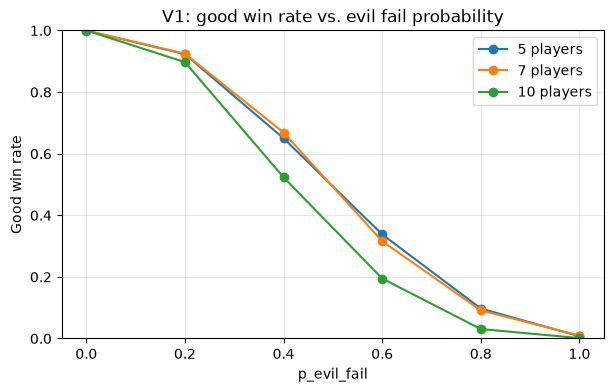

In [11]:
res = sweep("p_evil_fail", [0.0, 0.2, 0.4, 0.6, 0.8, 1.0], n_games=1500)
fig, ax = plt.subplots(figsize=(7, 4))
for n, grp in res.groupby("n_players"):
    ax.plot(grp.p_evil_fail, grp.good_win_rate, marker="o", label=f"{n} players")
ax.set_xlabel("p_evil_fail"); ax.set_ylabel("Good win rate"); ax.set_ylim(0, 1)
ax.set_title("V1: good win rate vs. evil fail probability"); ax.legend(); ax.grid(alpha=.3)
plt.show()

In [12]:
res = sweep("p_good_approve", [0.3, 0.45, 0.6, 0.75, 0.9], n_games=1500)
display(res.pivot(index="p_good_approve", columns="n_players", values=["good_win_rate", "evil_by_rejections"]).round(3))

good_win_rate               evil_by_rejections              
n_players                 5      7      10                 5      7      10
p_good_approve                                                             
0.30                   0.089  0.071  0.035              0.014  0.011  0.067
0.45                   0.089  0.094  0.037              0.002  0.000  0.003
0.60                   0.107  0.097  0.037              0.001  0.000  0.000
0.75                   0.117  0.111  0.047              0.000  0.000  0.000
0.90                   0.128  0.125  0.055              0.000  0.000  0.000

## 7. Roadmap for later versions

Each step changes only one or two layers.

**V2 — Belief tracking (agents layer).** Give good agents a `BeliefTracker` holding
P(player *i* is evil). Initialise it with the uniform prior `n_evil / (n−1)`. Update it
after each quest from the fail count, using exact Bayes over the possible evil subsets
(at most C(9,3)=84 hypotheses, so this is cheap). Proposals then favour low-suspicion
players, and votes approve with probability `sigmoid(β · (threshold − expected evil on team))`.
Vote-track pressure can be a new parameter (e.g. approve almost always on attempt 5).

**V3 — Special roles (roles + information model + engine).** Add Merlin, Assassin,
Percival, Morgana, Mordred and Oberon to `Role`. Swap `basic_knowledge` for a full
knowledge function. Override `_end_of_game` so a good win triggers the assassination.
Merlin gets a `p_merlin_reveal`-style parameter that trades good play against the
assassination risk.

**V4 — Strategic evil (agents layer).** Coordinate fail cards to avoid double fails on
small teams, play success early to build trust (`p_evil_fail` per quest index), and vote
in ways that hide alignment.

**V5 — Inference from votes.** Feed the public vote log into the belief tracker
(e.g. P(approve | evil, evil-on-team) learned from simulated games). This closes the loop:
simulated data calibrates the agents.